In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [9]:
df = pd.read_csv('5-sales_data_sample.csv', encoding='unicode_escape')
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [6]:
df.isnull().sum()

ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

In [7]:
df.dropna(inplace=True)

In [8]:
df.info()

<class 'pandas.DataFrame'>
Index: 147 entries, 10 to 2791
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       147 non-null    int64  
 1   QUANTITYORDERED   147 non-null    int64  
 2   PRICEEACH         147 non-null    float64
 3   ORDERLINENUMBER   147 non-null    int64  
 4   SALES             147 non-null    float64
 5   ORDERDATE         147 non-null    str    
 6   STATUS            147 non-null    str    
 7   QTR_ID            147 non-null    int64  
 8   MONTH_ID          147 non-null    int64  
 9   YEAR_ID           147 non-null    int64  
 10  PRODUCTLINE       147 non-null    str    
 11  MSRP              147 non-null    int64  
 12  PRODUCTCODE       147 non-null    str    
 13  CUSTOMERNAME      147 non-null    str    
 14  PHONE             147 non-null    str    
 15  ADDRESSLINE1      147 non-null    str    
 16  ADDRESSLINE2      147 non-null    str    
 17  CITY       

In [11]:
# We are clustering based on 'SALES', 'QUANTITYORDERED', PRICEEACH'
X = df[['SALES', 'QUANTITYORDERED', 'PRICEEACH']]

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [16]:
from sklearn.cluster import KMeans

inertia = []
K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

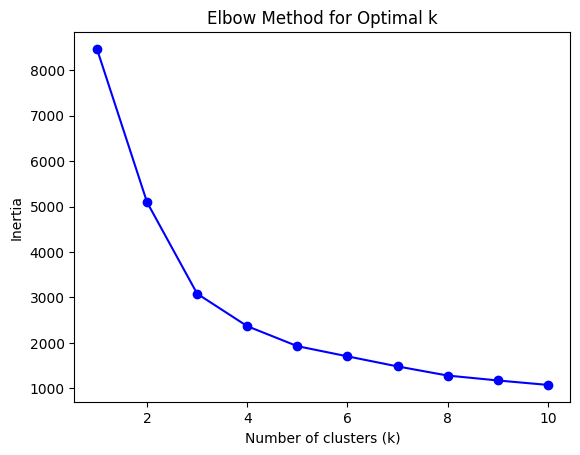

In [17]:
plt.plot(K, inertia, 'bo-')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')

plt.title('Elbow Method for Optimal k')
plt.show()

In [18]:
optimal_k = 4

kmeans = KMeans(n_clusters=optimal_k, random_state=42)
df['Cluster'] = kmeans.fit_predict(X_scaled)
# Check cluster assignments
df[['SALES', 'QUANTITYORDERED', 'PRICEEACH', 'Cluster']]

,SALES,QUANTITYORDERED,PRICEEACH,Cluster
0,2871.00,30,95.70,3
1,2765.90,34,81.35,3
2,3884.34,41,94.74,1
3,3746.70,45,83.26,0
4,5205.27,49,100.00,1
...,...,...,...,...
2818,2244.40,20,100.00,3
2819,3978.51,29,100.00,3
2820,5417.57,43,100.00,1
2821,2116.16,34,62.24,2
